        # Lesson 8.7 · Project 3: Crop Disease Classification
        ### A CNN that tells healthy leaves from leaf spot, blight and rust: evaluated the way an agronomist would

        | | |
        |---|---|
        | ⏱️ **Time** | about 120 minutes |
        | 📚 **Before you start** | Lessons 8.5 – 8.6 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Build, train and evaluate a **multi-class CNN** with **augmentation**
- Evaluate beyond accuracy: **per-class recall/precision**, **confidence thresholds and abstention**, **robustness to perturbations**
- Explain a prediction with an **occlusion-sensitivity heat-map**
- Know the **transfer-learning recipe** for real photos (PlantVillage) and the pitfalls of synthetic data

> 🌾 **The story so far.** Extension officers want a phone app: photograph a leaf, get a diagnosis. A *missed* disease can wipe out a field; a *false alarm* wastes a spray. So the question isn't just *"how accurate?"* but *"accurate **where it matters**, and honest about doubt."*

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
torch.set_num_threads(1)
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · The data

> ⚠️ **Honesty box.** Real crop-disease models are trained on photographs (e.g. the public *PlantVillage* set: ~54,000 labelled leaf images). So that this lesson runs anywhere,
> offline, in minutes, we use a **synthetic leaf generator** (`ag.make_leaf_dataset`): 48×48 images of four classes with random backgrounds, lighting, leaf pose and noise.
> The *workflow* is identical to the real thing. Section 8 shows exactly how to swap in real photos.

| Class | Visual cue (what a human agronomist looks for) |
|---|---|
| **healthy** | uniform green, maybe a stray speck |
| **leaf_spot** | several small dark lesions ringed with yellow |
| **blight** | one large dark patch creeping in from the edge |
| **rust** | many tiny orange pustules |

images: (2400, 48, 48, 3) | classes: ['healthy', 'leaf_spot', 'blight', 'rust'] | counts: [600 600 600 600]


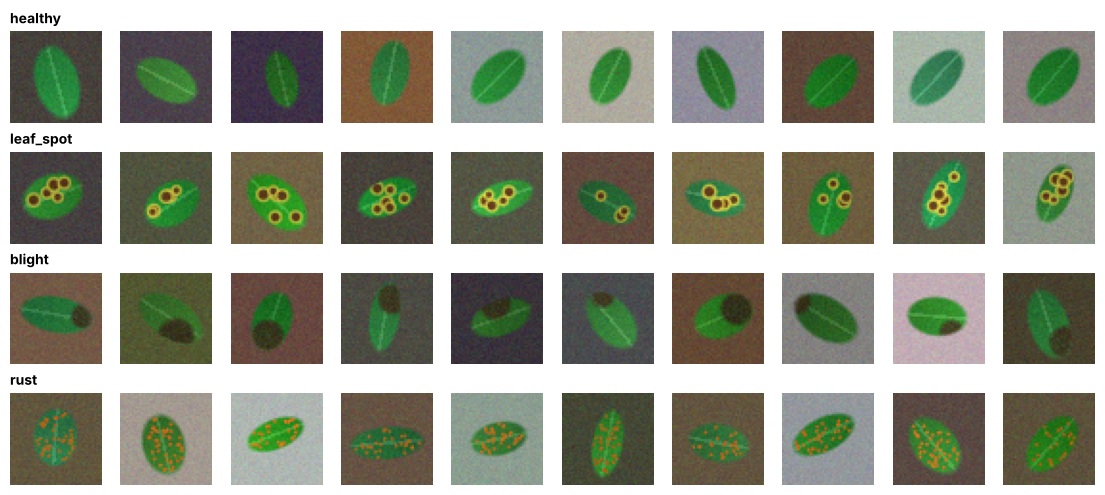

In [2]:
X_all, y_all, names = ag.load_leaf_dataset()
print("images:", X_all.shape, "| classes:", names, "| counts:", np.bincount(y_all))
fig, axes = plt.subplots(4, 10, figsize=(14, 6))
for c in range(4):
    for k, i in enumerate(np.where(y_all == c)[0][:10]):
        axes[c, k].imshow(X_all[i]); axes[c, k].axis("off")
    axes[c, 0].set_title(names[c], fontsize=10, loc="left")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
idx_tr, idx_tmp = train_test_split(np.arange(len(y_all)), test_size=0.3, stratify=y_all, random_state=0)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.5, stratify=y_all[idx_tmp], random_state=0)
to_t = lambda a: torch.tensor(a.astype(np.float32) / 255.0).permute(0, 3, 1, 2)
Xt = to_t(X_all); mean, std = Xt[idx_tr].mean((0, 2, 3), keepdim=True), Xt[idx_tr].std((0, 2, 3), keepdim=True)
Xn = (Xt - mean) / std; yt = torch.tensor(y_all, dtype=torch.long)
Xtr, ytr, Xva, yva, Xte, yte = Xn[idx_tr], yt[idx_tr], Xn[idx_va], yt[idx_va], Xn[idx_te], yt[idx_te]
print("train / val / test:", len(Xtr), len(Xva), len(Xte))

train / val / test: 1680 360 360


## 2 · A classical baseline: colour histograms

Before any CNN: describe each image by a **colour histogram** (8 bins per RGB channel = 24 numbers) and fit logistic regression. Disease changes the colour distribution (dark browns, oranges), but random backgrounds and lighting swamp that signal, and *where* the colour appears (a ring? a patch? scattered dots?) is invisible to a histogram. Expect a weak result: that weakness is the case for CNNs.

---
### 🧩 Exercise 1: Colour-histogram baseline  ⭐⭐

Write `color_hist(images_uint8)` returning an array of shape `(n, 24)`: for each image, the **normalised** (sum to 1 per channel) 8-bin histogram of each of the R, G, B channels (pixel range 0–255), concatenated.
Fit `LogisticRegression(max_iter=3000)` on the training indices and store the test accuracy in `hist_acc`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`np.histogram(img[..., ch].ravel(), bins=8, range=(0, 256))[0]` gives raw counts for one channel.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Divide by the number of pixels to normalise: `/ img[..., ch].size`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`F_all = color_hist(X_all)`; `LogisticRegression(max_iter=3000).fit(F_all[idx_tr], y_all[idx_tr]).score(F_all[idx_te], y_all[idx_te])`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [4]:
def color_hist(imgs):
    feats = []
    for img in imgs:
        f = [np.histogram(img[..., ch].ravel(), bins=8, range=(0, 256))[0] / img[..., ch].size for ch in range(3)]
        feats.append(np.concatenate(f))
    return np.array(feats)

F_all = color_hist(X_all)
hist_acc = float(LogisticRegression(max_iter=3000).fit(F_all[idx_tr], y_all[idx_tr]).score(F_all[idx_te], y_all[idx_te]))
print(F_all.shape, "| baseline test accuracy:", round(hist_acc, 3))

(2400, 24) | baseline test accuracy: 0.397


In [5]:
ag.check("features have shape (n, 24)", F_all is not None and F_all.shape == (len(X_all), 24))
ag.check("histograms sum to 1 per channel", F_all is not None and np.allclose(F_all[:, :8].sum(1), 1))
ag.check("baseline is above random guessing (25 %), but not by much", hist_acc is not None and hist_acc > 0.30)

✅  features have shape (n, 24)
✅  histograms sum to 1 per channel
✅  baseline is above random guessing (25 %), but not by much


True

---
## 3 · The CNN with augmentation
Leaves have no canonical orientation, so **flips and 90° rotations** preserve the label: free invariance. We also jitter brightness (sunlight varies).

trained 17 epochs in 31s | parameters 34,480 | TEST accuracy 0.986


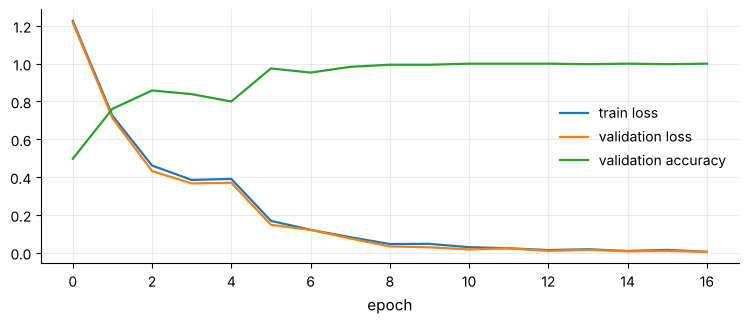

In [6]:
def block(cin, cout, pool=True):
    L = [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU()]
    return nn.Sequential(*L, nn.MaxPool2d(2)) if pool else nn.Sequential(*L)

class LeafNet(nn.Module):
    def __init__(self, n_classes=4, w=12):
        super().__init__()
        self.features = nn.Sequential(block(3, w), block(w, 2 * w), block(2 * w, 4 * w), block(4 * w, 4 * w, pool=False))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(4 * w, n_classes))
    def forward(self, x): return self.head(self.features(x))

def augment(xb):
    xb = xb.clone()
    if np.random.rand() < .5: xb = xb.flip(-1)
    if np.random.rand() < .5: xb = xb.flip(-2)
    xb = torch.rot90(xb, k=np.random.randint(4), dims=(2, 3))
    return xb * (1 + 0.2 * (torch.rand(len(xb), 1, 1, 1) - 0.5))

def train_cnn(model, Xtr, ytr, Xva, yva, epochs=25, lr=3e-3, batch=64, patience=6, aug=None, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3); lossf = nn.CrossEntropyLoss()
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * int(np.ceil(len(Xtr) / batch)))
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch, shuffle=True)
    best, best_state, wait, hist = -1, None, 0, []
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            if aug: xb = aug(xb)
            opt.zero_grad(); lossf(model(xb), yb).backward(); opt.step(); sched.step()
        model.eval()
        with torch.no_grad():
            tl = lossf(model(Xtr[:600]), ytr[:600]).item(); out = model(Xva); vl = lossf(out, yva).item(); va = (out.argmax(1) == yva).float().mean().item()
        hist.append((tl, vl, va))
        if va > best: best, best_state, wait = va, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model, np.array(hist)

import time; t0 = time.time()
leaf, hist = train_cnn(LeafNet(), Xtr, ytr, Xva, yva, aug=augment)
with torch.no_grad(): logits = leaf(Xte); probs = torch.softmax(logits, 1); pred = logits.argmax(1)
test_acc = (pred == yte).float().mean().item()
print(f"trained {len(hist)} epochs in {time.time()-t0:.0f}s | parameters {sum(p.numel() for p in leaf.parameters()):,} | TEST accuracy {test_acc:.3f}")
plt.figure(figsize=(9, 3.3)); plt.plot(hist[:, 0], label="train loss"); plt.plot(hist[:, 1], label="validation loss"); plt.plot(hist[:, 2], label="validation accuracy"); plt.legend(); plt.xlabel("epoch"); plt.show()

---
## 4 · Evaluate like an agronomist

Overall accuracy treats every error alike. Field reality doesn't.

| Metric | Question it answers | Why an agronomist cares |
|---|---|---|
| **Recall** of a disease class | *Of all truly diseased leaves, how many did we catch?* | a miss = untreated outbreak |
| **Precision** of a disease class | *When we say "blight", how often is it?* | a false alarm = wasted spray |
| **Confusion matrix** | *Which diseases get mixed up?* | guides data collection |

$\text{recall}_c=\dfrac{TP_c}{TP_c+FN_c}$ (row-wise), $\quad\text{precision}_c=\dfrac{TP_c}{TP_c+FP_c}$ (column-wise).

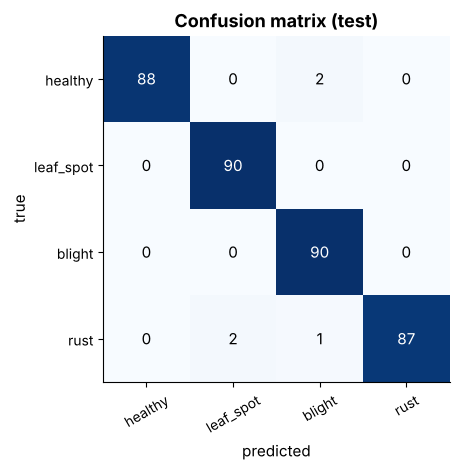

In [7]:
cm_ref = confusion_matrix(yte.numpy(), pred.numpy())
fig, ax = plt.subplots(figsize=(5, 4.5)); ax.imshow(cm_ref, cmap="Blues")
for i in range(4):
    for j in range(4): ax.text(j, i, cm_ref[i, j], ha="center", va="center", fontsize=11, color="white" if cm_ref[i, j] > cm_ref.max() / 2 else "black")
ax.set(xticks=range(4), yticks=range(4), xticklabels=names, yticklabels=names, xlabel="predicted", ylabel="true", title="Confusion matrix (test)"); ax.grid(False); plt.xticks(rotation=30); plt.show()

---
### 🧩 Exercise 2: Per-class precision and recall  ⭐⭐

From the confusion matrix `cm` (rows = true, columns = predicted), compute NumPy arrays `precision` and `recall` (length 4) **without** sklearn,
and name the class with the lowest recall in `weakest_class` (a string from `names`).

<details><summary>💡 Hint 1: gentle nudge</summary>

True positives are the diagonal: `tp = np.diag(cm)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Recall divides by the **row** sums (`cm.sum(axis=1)`), precision by the **column** sums (`cm.sum(axis=0)`).

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`weakest_class = names[int(recall.argmin())]`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [8]:
cm = cm_ref.copy()
tp = np.diag(cm)
recall = tp / cm.sum(axis=1)
precision = tp / cm.sum(axis=0)
weakest_class = names[int(recall.argmin())]
print(dict(zip(names, [round(float(v), 3) for v in recall])), "-> weakest:", weakest_class)

{'healthy': 0.978, 'leaf_spot': 1.0, 'blight': 1.0, 'rust': 0.967} -> weakest: rust


In [9]:
ag.check("recall = diagonal / row sums", recall is not None and np.allclose(recall, np.diag(cm_ref) / cm_ref.sum(1)))
ag.check("precision = diagonal / column sums", precision is not None and np.allclose(precision, np.diag(cm_ref) / cm_ref.sum(0)))
ag.check("weakest_class is a class name", weakest_class in names)

✅  recall = diagonal / row sums
✅  precision = diagonal / column sums
✅  weakest_class is a class name


True

### Knowing when you don't know: confidence and abstention
A trustworthy app says *"I'm not sure: please send a clearer photo"* instead of guessing. The model's **softmax confidence** (max probability) is a simple uncertainty signal.
Raise the confidence threshold: **coverage** (share of images we answer) falls, but **accuracy on the answered ones** rises.

---
### 🧩 Exercise 3: Selective prediction  ⭐⭐

With `conf` (max softmax probability per test image) and `correct` (boolean: prediction right?), compute for each threshold in `thresholds = [0.5, 0.7, 0.9, 0.99]`:
`coverage` = fraction of images with `conf >= t`, and `acc_answered` = accuracy among those images.
Store both as lists. Also find `t_for_99`: the **smallest** threshold in `np.linspace(0.5, 0.999, 200)` whose answered-accuracy is ≥ 0.99 (or `None` if none).

<details><summary>💡 Hint 1: gentle nudge</summary>

`answered = conf >= t`; `coverage.append(answered.mean())`; `acc_answered.append(correct[answered].mean())` (guard against an empty selection).

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Loop over `np.linspace(0.5, 0.999, 200)` and `break` at the first that satisfies the accuracy target.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`correct` is `(pred == yte).numpy()`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [10]:
conf = probs.max(1).values.numpy()
correct = (pred == yte).numpy()
thresholds = [0.5, 0.7, 0.9, 0.99]
coverage, acc_answered = [], []
for t in thresholds:
    answered = conf >= t
    coverage.append(float(answered.mean()))
    acc_answered.append(float(correct[answered].mean()) if answered.any() else float("nan"))
t_for_99 = None
for t in np.linspace(0.5, 0.999, 200):
    sel = conf >= t
    if sel.any() and correct[sel].mean() >= 0.99:
        t_for_99 = float(t); break
print("coverage:", np.round(coverage, 3), "| accuracy on answered:", np.round(acc_answered, 3), "| threshold for 99 %:", t_for_99)

coverage: [0.997 0.983 0.944 0.647] | accuracy on answered: [0.986 0.997 1.    1.   ] | threshold for 99 %: 0.535105527638191


In [11]:
ag.check("four coverage values, non-increasing", len(coverage) == 4 and all(a >= b for a, b in zip(coverage, coverage[1:])))
ag.check("coverage at t=0.5 is ~100 % (4 classes => max prob >= 0.25)", coverage[0] > 0.97)
ag.check("accuracy on answered images is at least the overall accuracy at the strictest threshold", np.nanmax(acc_answered) >= correct.mean() - 1e-9)
ag.check("t_for_99 is None or a probability", t_for_99 is None or 0.5 <= t_for_99 <= 1)

✅  four coverage values, non-increasing
✅  coverage at t=0.5 is ~100 % (4 classes => max prob >= 0.25)
✅  accuracy on answered images is at least the overall accuracy at the strictest threshold
✅  t_for_99 is None or a probability


True

---
## 5 · Why did it say that? Occlusion sensitivity

Slide a grey square over the image; at each position record how much the model's **confidence in the true class drops**.
Where covering the image hurts most, the model is *looking*. A good disease detector should look at the **lesions**, not the background.

---
### 🧩 Exercise 4: Occlusion-sensitivity map  ⭐⭐⭐

Implement `occlusion_map(model, x, label, patch=10, stride=4)` for one normalised image `x` of shape `(3, 48, 48)`:
for each top-left position on the grid `range(0, 48 - patch + 1, stride)`, set that patch to **0** (the mean colour, since the data are normalised), run the model,
and record `base_prob - prob_after_occlusion` for the true `label`. Return a 2-D NumPy array (rows = y positions, columns = x positions).

<details><summary>💡 Hint 1: gentle nudge</summary>

`base = softmax(model(x[None]))[0, label]`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`xo = x.clone(); xo[:, y:y+patch, x_:x_+patch] = 0`: careful not to shadow the variable `x`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Run everything under `torch.no_grad()` and with `model.eval()`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [12]:
def occlusion_map(model, x, label, patch=10, stride=4):
    model.eval()
    pos = list(range(0, x.shape[1] - patch + 1, stride))
    with torch.no_grad():
        base = torch.softmax(model(x[None]), 1)[0, label].item()
        out = np.zeros((len(pos), len(pos)))
        for a, r in enumerate(pos):
            for b, c in enumerate(pos):
                xo = x.clone(); xo[:, r:r + patch, c:c + patch] = 0
                out[a, b] = base - torch.softmax(model(xo[None]), 1)[0, label].item()
    return out

i_blight = int(torch.where(yte == 2)[0][0])
omap = occlusion_map(leaf, Xte[i_blight], 2)
print(omap.shape, "max drop in confidence:", round(omap.max(), 3))

(10, 10) max drop in confidence: 0.921


In [13]:
ag.check("map is 10 x 10 for patch 10, stride 4 on 48 px", omap is not None and omap.shape == (10, 10))
ag.check("some occlusion position lowers the confidence", omap is not None and omap.max() > 0.01)

✅  map is 10 x 10 for patch 10, stride 4 on 48 px
✅  some occlusion position lowers the confidence


True

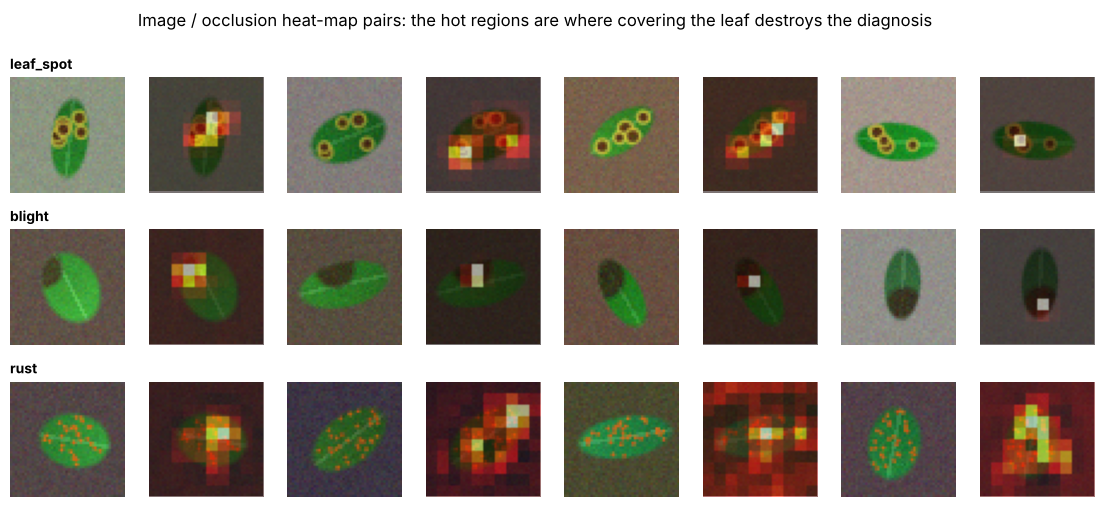

In [14]:
fig, axes = plt.subplots(3, 8, figsize=(14, 5.6))
for ci, c in enumerate([1, 2, 3]):                                       # a few examples of each disease
    for k, i in enumerate(torch.where((yte == c) & (pred == yte))[0][:4].tolist()):
        m = occlusion_map(leaf, Xte[i], c)
        axes[ci, 2 * k].imshow(X_all[idx_te[i]]); axes[ci, 2 * k].axis("off")
        axes[ci, 2 * k + 1].imshow(X_all[idx_te[i]]); axes[ci, 2 * k + 1].imshow(np.kron(m, np.ones((4, 4))), alpha=.55, cmap="hot", extent=(0, 48, 48, 0)); axes[ci, 2 * k + 1].axis("off")
    axes[ci, 0].set_title(names[c], fontsize=10, loc="left")
plt.suptitle("Image / occlusion heat-map pairs: the hot regions are where covering the leaf destroys the diagnosis", y=0.99); plt.show()

## 6 · Robustness: will it survive the field?
Photos from phones in a field are darker, blurrier, noisier than lab images. Stress-test: perturb the *test* images and watch accuracy.

In [15]:
def acc_on(X):
    with torch.no_grad(): return (leaf(X).argmax(1) == yte).float().mean().item()

perturb = {
    "clean": lambda X: X,
    "darker (x0.6)": lambda X: (X * std + mean) * 0.6,
    "brighter (x1.4)": lambda X: ((X * std + mean) * 1.4).clamp(0, 1),
    "noise σ=0.10": lambda X: (X * std + mean) + 0.10 * torch.randn_like(X),
    "blur (3x3 mean)": lambda X: F.avg_pool2d(X * std + mean, 3, 1, 1),
}
rob = {}
for k, f in perturb.items():
    Xp = f(Xte) if k == "clean" else (f(Xte) - mean) / std               # re-normalise perturbed pixel images
    rob[k] = acc_on(Xp)
pd.Series(rob, name="test accuracy").round(3).to_frame()

,test accuracy
clean,0.986
darker (x0.6),0.672
brighter (x1.4),0.850
noise σ=0.10,0.394
blur (3x3 mean),0.664


If accuracy craters under a perturbation you expect in the field, **add that perturbation to your augmentation** (and re-test). This is how robustness is *engineered*, not hoped for.

## 7 · Choosing a decision policy
Suppose a missed disease costs **10×** a false alarm. Declaring a leaf healthy is only worth it if $10\cdot P(\text{sick}) < P(\text{healthy})$, i.e. $P(\text{healthy})>\tfrac{10}{11}$. So, rather than taking `argmax`, flag "diseased" **unless** the model is at least 91 % sure the leaf is healthy.

In [16]:
p_healthy = probs[:, 0].numpy(); truly_sick = (yte != 0).numpy()
for thr in (0.5, 10 / 11):
    flagged_sick = p_healthy < thr
    missed, false_alarm = int((truly_sick & ~flagged_sick).sum()), int((~truly_sick & flagged_sick).sum())
    print(f"flag 'diseased' unless P(healthy) >= {thr:.3f}:  missed diseases = {missed}, false alarms = {false_alarm}, expected cost = {10 * missed + false_alarm}")

flag 'diseased' unless P(healthy) >= 0.500:  missed diseases = 0, false alarms = 2, expected cost = 2
flag 'diseased' unless P(healthy) >= 0.909:  missed diseases = 0, false alarms = 4, expected cost = 4


Here the model is so accurate that the stricter rule merely adds a couple of false alarms and saves nothing: there were no misses to prevent. With a weaker model (try swapping in the colour-histogram baseline!) the cost-aware threshold saves a lot.
A model is a **probability estimator**; the *decision rule* is a separate, business-driven choice. Always tune the threshold to the costs.

## 8 · Going real: the transfer-learning recipe
Real photos are large, varied, and you rarely have millions. The standard recipe: start from a network **pre-trained on ImageNet** and re-train only the head (then optionally fine-tune the rest).
The cell below is **not executed here** (needs `torchvision`, internet for the weights, and a folder of photos like `plantvillage/<class_name>/*.jpg`).

In [17]:
RUN_TRANSFER = False          # set True on your own machine after:  pip install torchvision  and downloading PlantVillage

if RUN_TRANSFER:
    from torchvision import datasets, transforms, models
    tf_train = transforms.Compose([transforms.RandomResizedCrop(224, scale=(0.7, 1.0)), transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
                                   transforms.ColorJitter(0.3, 0.3, 0.2), transforms.ToTensor(),
                                   transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])          # ImageNet statistics
    data = datasets.ImageFolder("plantvillage", transform=tf_train)
    loader_real = DataLoader(data, batch_size=32, shuffle=True)
    net_real = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for p in net_real.parameters(): p.requires_grad = False                     # 1) freeze the pre-trained backbone
    net_real.fc = nn.Linear(net_real.fc.in_features, len(data.classes))          # 2) new classification head (trainable)
    opt = torch.optim.AdamW(net_real.fc.parameters(), lr=1e-3)
    # 3) train a few epochs with the usual loop; 4) optionally unfreeze `layer4` and fine-tune with lr=1e-4
    print("classes:", data.classes)
else:
    print("Transfer-learning cell skipped (RUN_TRANSFER = False).")

Transfer-learning cell skipped (RUN_TRANSFER = False).


**Real-world pitfalls to remember**

| Pitfall | What goes wrong | Defence |
|---|---|---|
| **Background shortcut** | in PlantVillage all diseased leaves were photographed on one background; models can "cheat" on the background | occlusion maps, hold-out *backgrounds/sites*, in-field test photos |
| **Same-plant leakage** | photos of one plant in both train and test | split by *plant / field / date*, not by image |
| **Class imbalance** | rare diseases ignored | class-weighted loss, over-sampling, report per-class recall |
| **Distribution shift** | new camera, season, variety | monitor in production; keep collecting labelled field images |
| **Over-trust** | farmers act on wrong advice | abstain when unsure; keep a human in the loop |

## 🏁 Project extensions
1. Add a **fifth class** ("nutrient deficiency": yellowing) to the generator and retrain.
2. Train with **class weights** after making `blight` rare (50 images); how does per-class recall change?
3. Add **Gaussian noise + blur** to the augmentation and re-run the robustness table.
4. Build `diagnose(image) -> (label, confidence, "please retake photo" | advice)` using the abstention threshold.
5. On your machine: run the transfer-learning cell on real PlantVillage data and compare to this model.

## 🎓 Mini-quiz
1. Recall 0.90 for blight, precision 0.99. What does each number mean for the farmer?
2. Why split by plant rather than by image?
3. Why does a high-confidence threshold lower *coverage*?

<details><summary>Answers</summary>

1. 10 % of blighted leaves are missed; but almost every "blight" alert is correct. 2. Leaves of the same plant look alike; a random split puts near-duplicates in train and test and inflates accuracy. 3. Fewer images clear the bar, so the app answers fewer of them (and defers the rest).
</details>

        ---
        ## 🧾 Recap
        - Workflow: **baseline → CNN → augmentation → per-class metrics → abstention → explanation → robustness → decision policy**.
- Report **recall and precision per class**; choose thresholds from **costs**, not from `argmax`.
- **Occlusion maps** reveal what the model looks at; **perturbation tests** reveal fragility.
- Real data: use **transfer learning**, split by plant/site, beware background shortcuts and distribution shift.

**Next up:** Lesson 8.8: sequences: RNNs, LSTMs and GRUs, from a hand-built recurrent cell to PyTorch's layers.